In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split



In [3]:
df_customers = pd.read_csv('customers.csv')
df_loans = pd.read_csv('loans.csv')
df_bureau = pd.read_csv('bureau_data.csv')

In [4]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [5]:
df_customers.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001


In [6]:
df_loans.head(2)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


In [7]:
df = pd.merge(df_customers, df_loans, on='cust_id')
df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False


In [8]:
df_bureau.head(2)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4


In [9]:
df = pd.merge(df, df_bureau, on='cust_id')
df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4


In [10]:
df['default'] = df['default'].astype('int')
df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,0,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,0,3,1,96,12,60,5,4


In [11]:
X = df.drop([ 'default'], axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=40)

df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

In [12]:
df_train.shape , df_test.shape

((40000, 33), (10000, 33))

In [13]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 48
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [14]:
df_train.residence_type.unique()

<ArrowStringArray>
['Owned', 'Rented', 'Mortgage', nan]
Length: 4, dtype: str

In [15]:
mode_residence = df_train.residence_type.mode()[0]
mode_residence

'Owned'

In [16]:
df_train.fillna(mode_residence, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
33649,C33650,37,M,Married,Salaried,1061000,3,Owned,26,Kolkata,...,2022-12-03,2023-01-02,1,0,19,0,0,1,31,0
43700,C43701,42,M,Single,Salaried,283000,0,Owned,3,Ahmedabad,...,2023-12-05,2023-12-11,3,0,166,4,23,3,17,0
27039,C27040,52,F,Single,Self-Employed,207000,2,Owned,18,Mumbai,...,2022-04-06,2022-04-07,3,0,77,0,0,4,18,0
23128,C23129,35,M,Single,Self-Employed,7549000,0,Owned,21,Lucknow,...,2021-11-14,2021-11-24,2,1,46,4,28,4,75,0
35305,C35306,38,M,Single,Salaried,2096000,0,Rented,16,Pune,...,2023-02-02,2023-02-28,1,2,37,12,73,6,37,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27640,C27641,38,M,Married,Self-Employed,8355000,2,Owned,30,Mumbai,...,2022-04-28,2022-05-06,1,0,60,0,0,2,16,0
14501,C14502,40,M,Married,Self-Employed,1365000,3,Owned,24,Pune,...,2021-01-03,2021-01-15,1,2,12,9,52,1,70,0
30727,C30728,31,F,Single,Self-Employed,1323000,1,Mortgage,22,Pune,...,2022-08-19,2022-09-03,1,2,3,1,4,3,99,1
47323,C47324,41,F,Single,Self-Employed,904000,2,Mortgage,13,Lucknow,...,2024-04-15,2024-05-04,1,2,48,4,23,3,7,0


In [17]:
df_train.residence_type.unique()

<ArrowStringArray>
['Owned', 'Rented', 'Mortgage']
Length: 3, dtype: str

In [18]:
df_test.residence_type.unique()


<ArrowStringArray>
['Owned', 'Mortgage', 'Rented', nan]
Length: 4, dtype: str

In [19]:
mode_for_test = df_test.residence_type.mode()[0]   
mode_for_test 

'Owned'

In [20]:
df_test.fillna(mode_for_test, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
22599,C22600,30,F,Single,Salaried,125000,0,Owned,22,Ahmedabad,...,2021-10-26,2021-10-29,4,2,120,0,0,8,24,0
38540,C38541,18,M,Single,Self-Employed,10253000,0,Owned,15,Delhi,...,2023-05-31,2023-06-20,2,1,51,0,0,2,98,0
32995,C32996,33,M,Single,Salaried,493000,0,Owned,7,Chennai,...,2022-11-09,2022-11-20,3,2,84,0,0,6,68,0
37372,C37373,36,M,Single,Self-Employed,11812000,0,Mortgage,20,Chennai,...,2023-04-18,2023-05-14,3,1,93,0,0,7,39,0
26774,C26775,40,F,Married,Salaried,714000,4,Owned,8,Jaipur,...,2022-03-27,2022-04-26,4,1,68,0,0,5,69,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,C01461,38,M,Single,Salaried,1388000,0,Owned,30,Hyderabad,...,2019-09-15,2019-10-03,3,2,115,0,0,3,2,0
962,C00963,41,M,Married,Salaried,2219000,3,Rented,2,Bangalore,...,2019-08-28,2019-09-25,3,0,78,11,69,8,71,0
15554,C15555,49,M,Married,Self-Employed,903000,4,Mortgage,15,Pune,...,2021-02-11,2021-02-28,2,2,80,10,69,6,77,1
27631,C27632,48,F,Single,Self-Employed,2811000,1,Mortgage,10,Chennai,...,2022-04-28,2022-05-08,3,1,131,12,53,8,79,0


In [21]:
df_train.duplicated().sum()

np.int64(0)

In [22]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='str')

In [23]:
# Numerical columns
numerical_cols =  ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

# Categorical columns
categorical_cols = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']

print("Numerical Columns:")
print(numerical_cols)


Numerical Columns:
['age', 'income', 'number_of_dependants', 'years_at_current_address', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months', 'principal_outstanding', 'bank_balance_at_application', 'number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count', 'credit_utilization_ratio']


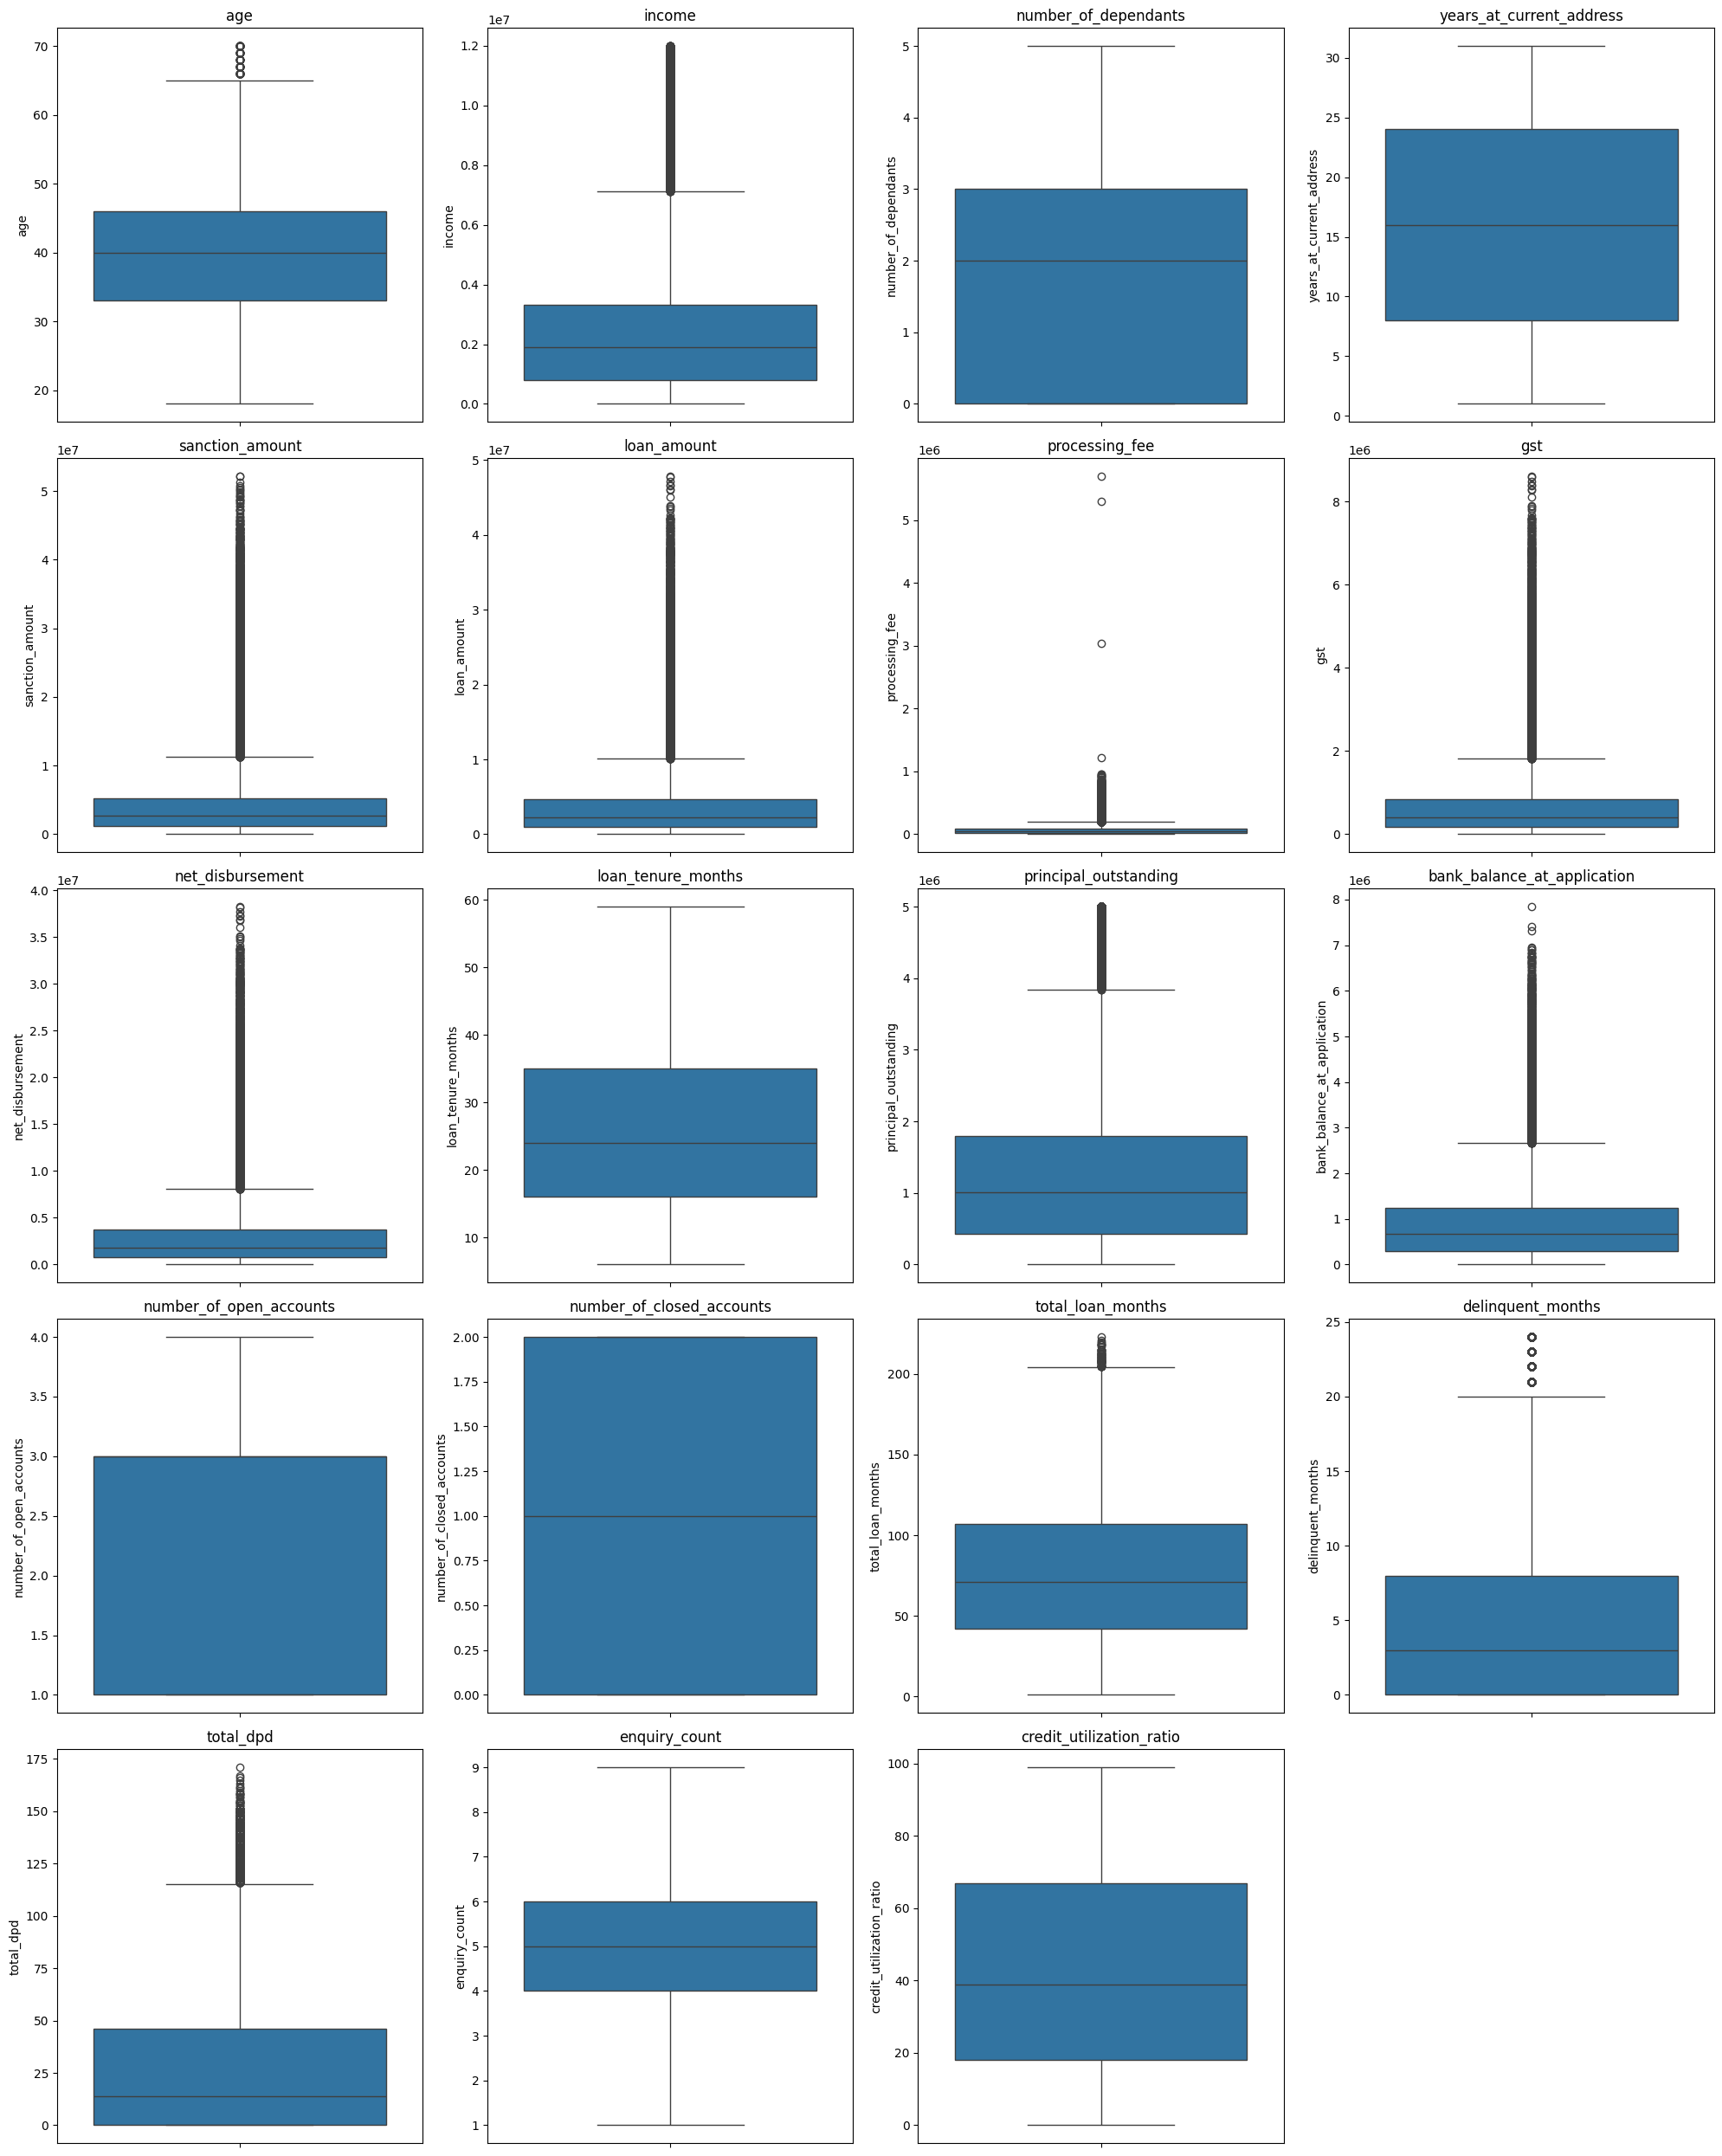

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(df_train[col], ax=axes[i])
    axes[i].set_title(col)

# Remove empty plots
for i in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

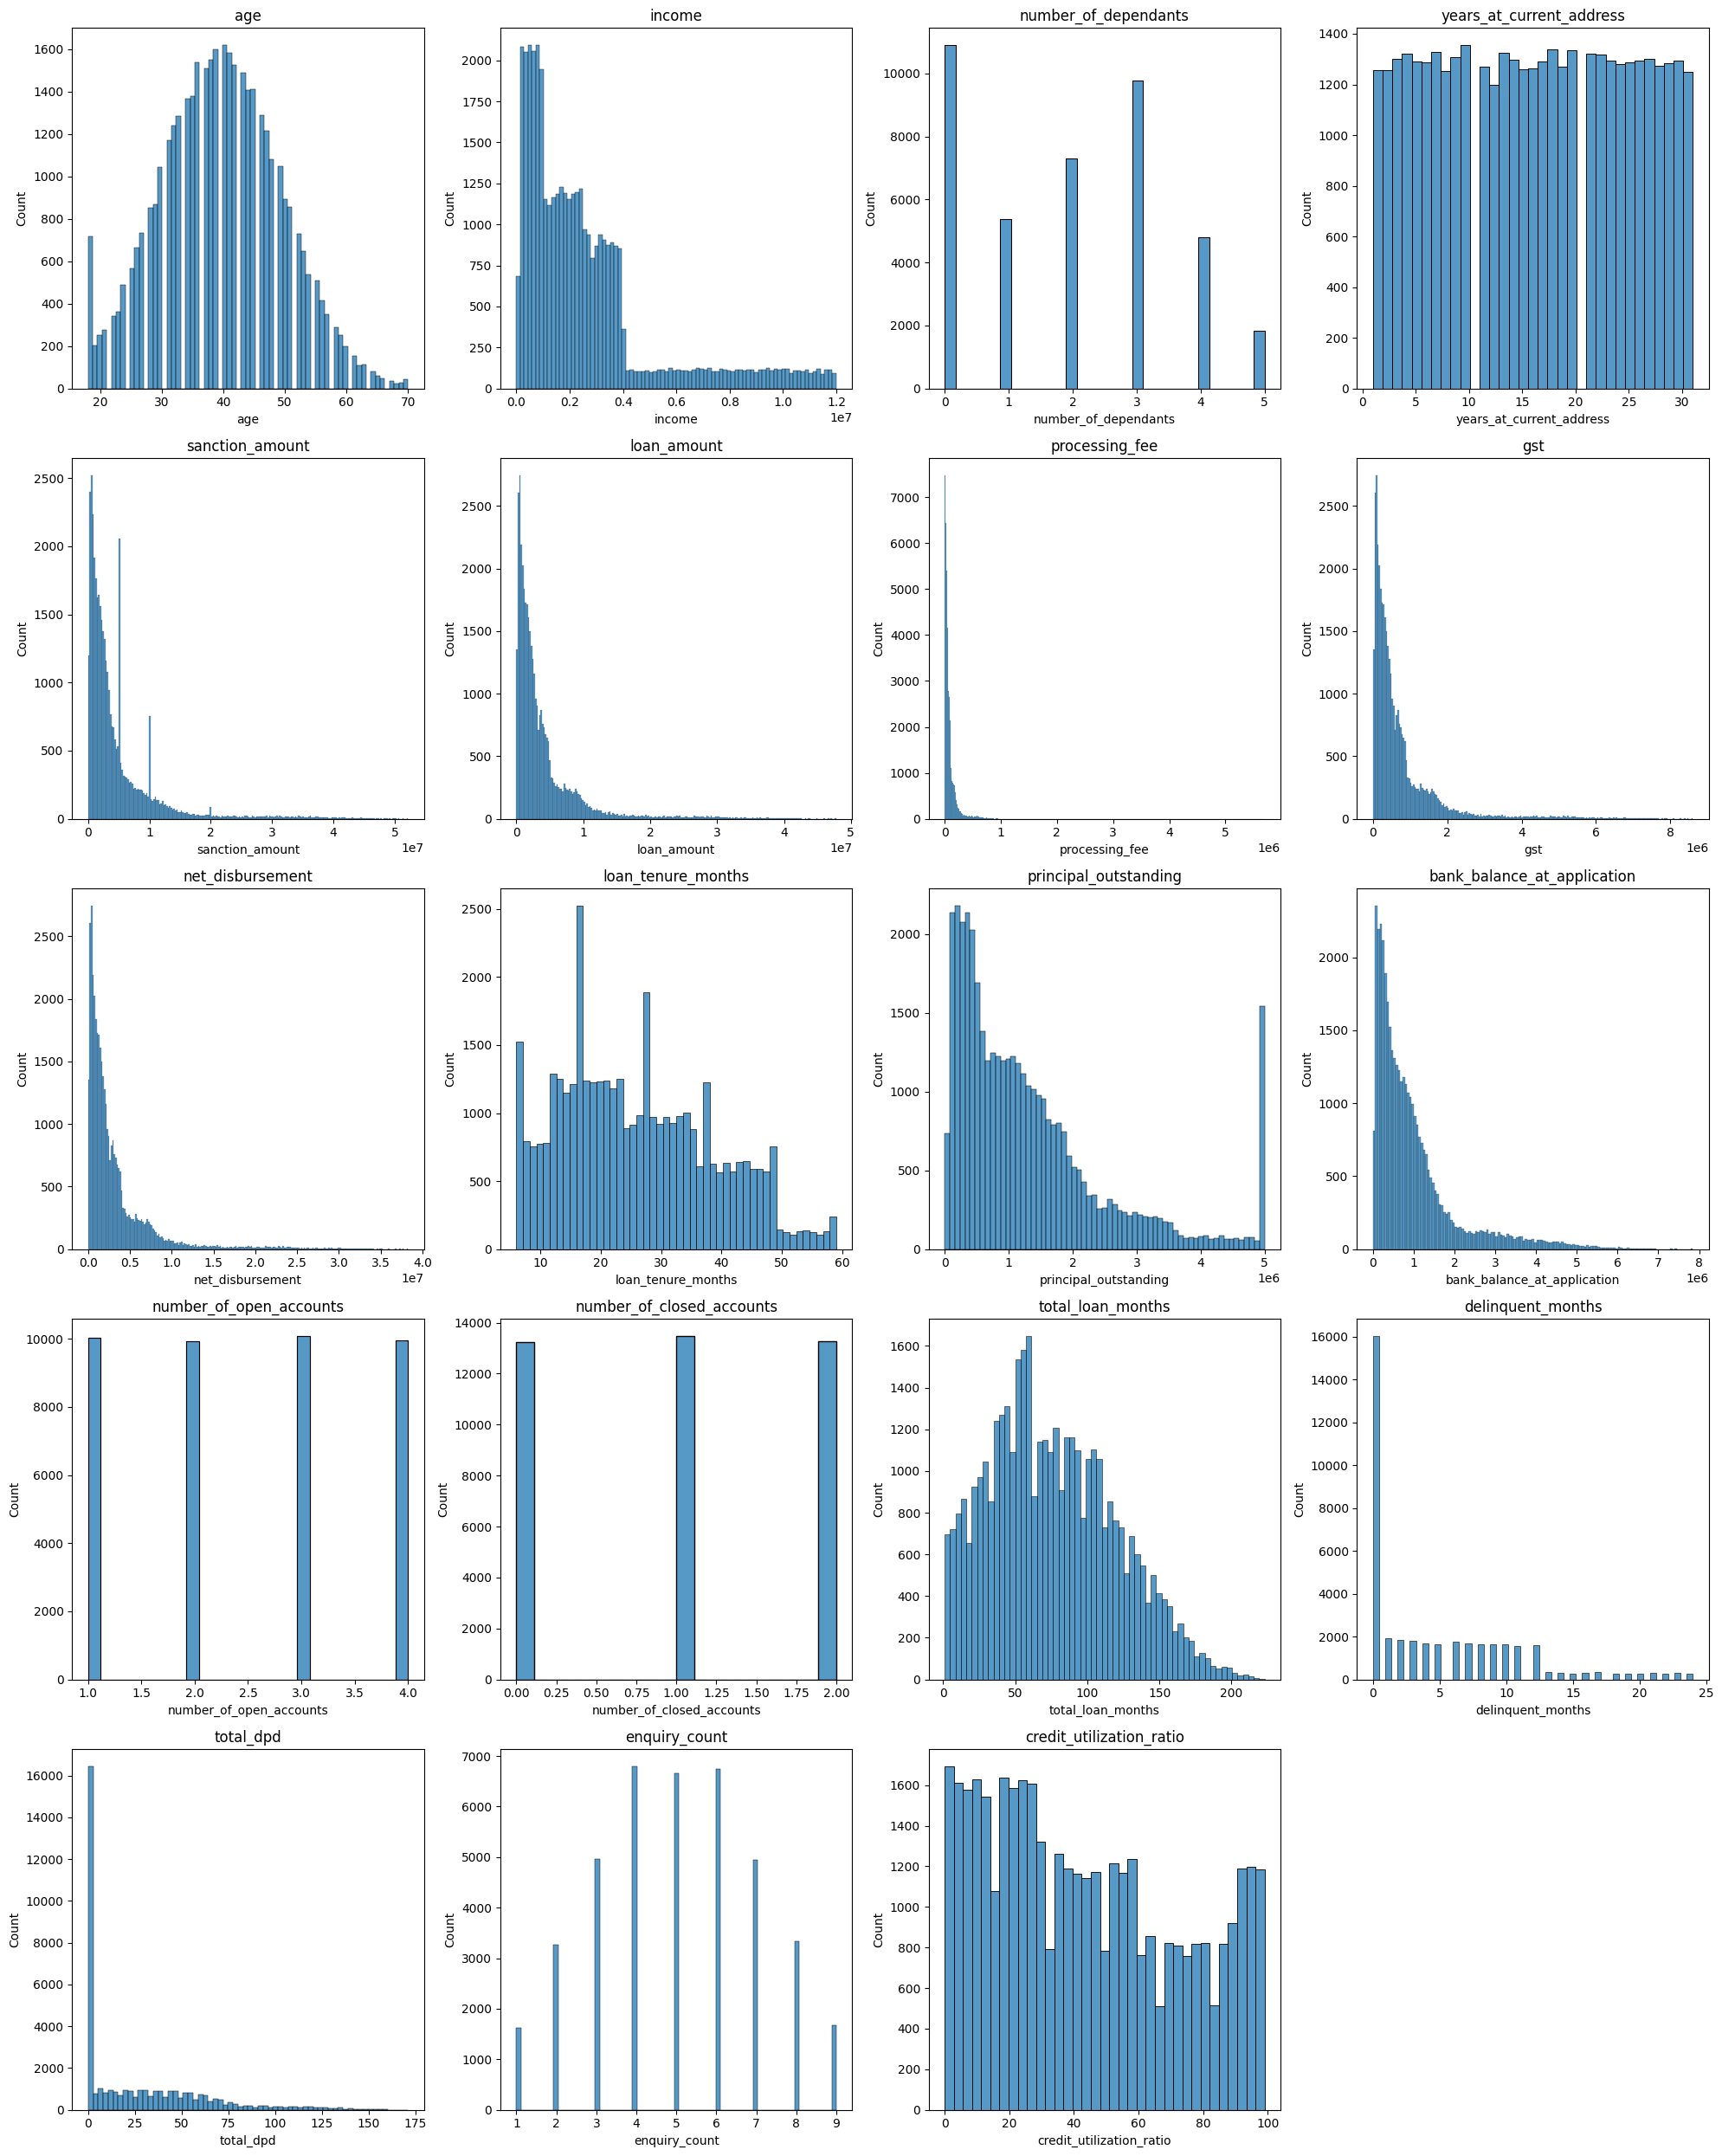

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 4
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df_train[col], ax=axes[i])
    axes[i].set_title(col)

# Remove empty plots
for i in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [26]:
df_train.processing_fee.describe()

count    4.000000e+04
mean     8.054547e+04
std      1.154181e+05
min      0.000000e+00
25%      1.938000e+04
50%      4.480000e+04
75%      9.256000e+04
max      5.698030e+06
Name: processing_fee, dtype: float64

In [27]:
df_train[(df_train.processing_fee / df_train.loan_amount) > 0.03][["loan_amount", "processing_fee"]]

,loan_amount,processing_fee
29305,2616000,3.036378e+06
28174,966000,1.214493e+06
9898,3626000,5.293544e+06
12294,4639000,5.698030e+06


In [28]:
df_train_1 = df_train[(df_train.processing_fee / df_train.loan_amount) < 0.03].copy()
df_train_1[(df_train_1.processing_fee / df_train_1.loan_amount) > 0.03][["loan_amount", "processing_fee"]]

,loan_amount,processing_fee


In [29]:
df_test = df_test[(df_test.processing_fee / df_test.loan_amount) < 0.03].copy()
df_test.shape

(9994, 33)

In [30]:
categorical_cols

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [31]:
for col in categorical_cols:
    print(col ,"-->", df_train_1[col].unique())

gender --> <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
marital_status --> <ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str
employment_status --> <ArrowStringArray>
['Salaried', 'Self-Employed']
Length: 2, dtype: str
residence_type --> <ArrowStringArray>
['Owned', 'Rented', 'Mortgage']
Length: 3, dtype: str
city --> <ArrowStringArray>
[  'Kolkata', 'Ahmedabad',    'Mumbai',   'Lucknow',      'Pune',   'Chennai',
     'Delhi', 'Hyderabad',    'Jaipur', 'Bangalore']
Length: 10, dtype: str
state --> <ArrowStringArray>
[  'West Bengal',       'Gujarat',   'Maharashtra', 'Uttar Pradesh',
    'Tamil Nadu',         'Delhi',     'Telangana',     'Rajasthan',
     'Karnataka']
Length: 9, dtype: str
zipcode --> [700001 380001 400001 226001 411001 600001 110001 500001 302001 560001]
loan_purpose --> <ArrowStringArray>
['Auto', 'Education', 'Home', 'Personal', 'Personaal']
Length: 5, dtype: str
loan_type --> <ArrowStringArray>
['Secured', 'Unsecured']
Length: 2, dtype: str
def

In [32]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal', 'Personal')
df_test['loan_purpose'] = df_test['loan_purpose'].replace('Personaal', 'Personal')
df_train_1['loan_purpose'].unique()

<ArrowStringArray>
['Auto', 'Education', 'Home', 'Personal']
Length: 4, dtype: str

<h3 align = "center" style = "color : yellow">EDA</h3>

In [33]:
numerical_cols

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

<Axes: xlabel='age', ylabel='Density'>

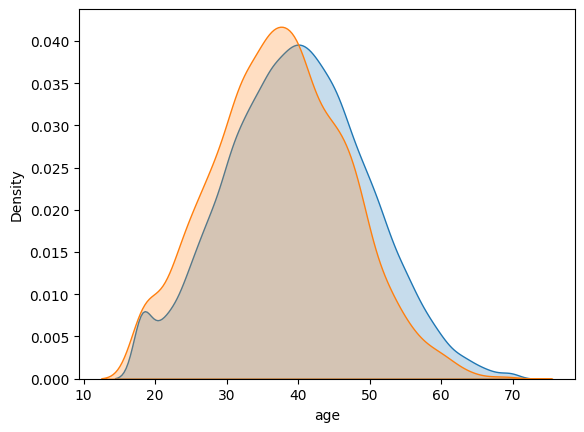

In [34]:
sns.kdeplot(df_train[df_train.default == 0]['age'], fill=True)
sns.kdeplot(df_train[df_train.default == 1]['age'], fill=True)

Insights
1. Orange graph is shifted a little bit to the left of blue graph which indicates that people with young age are more likely to default

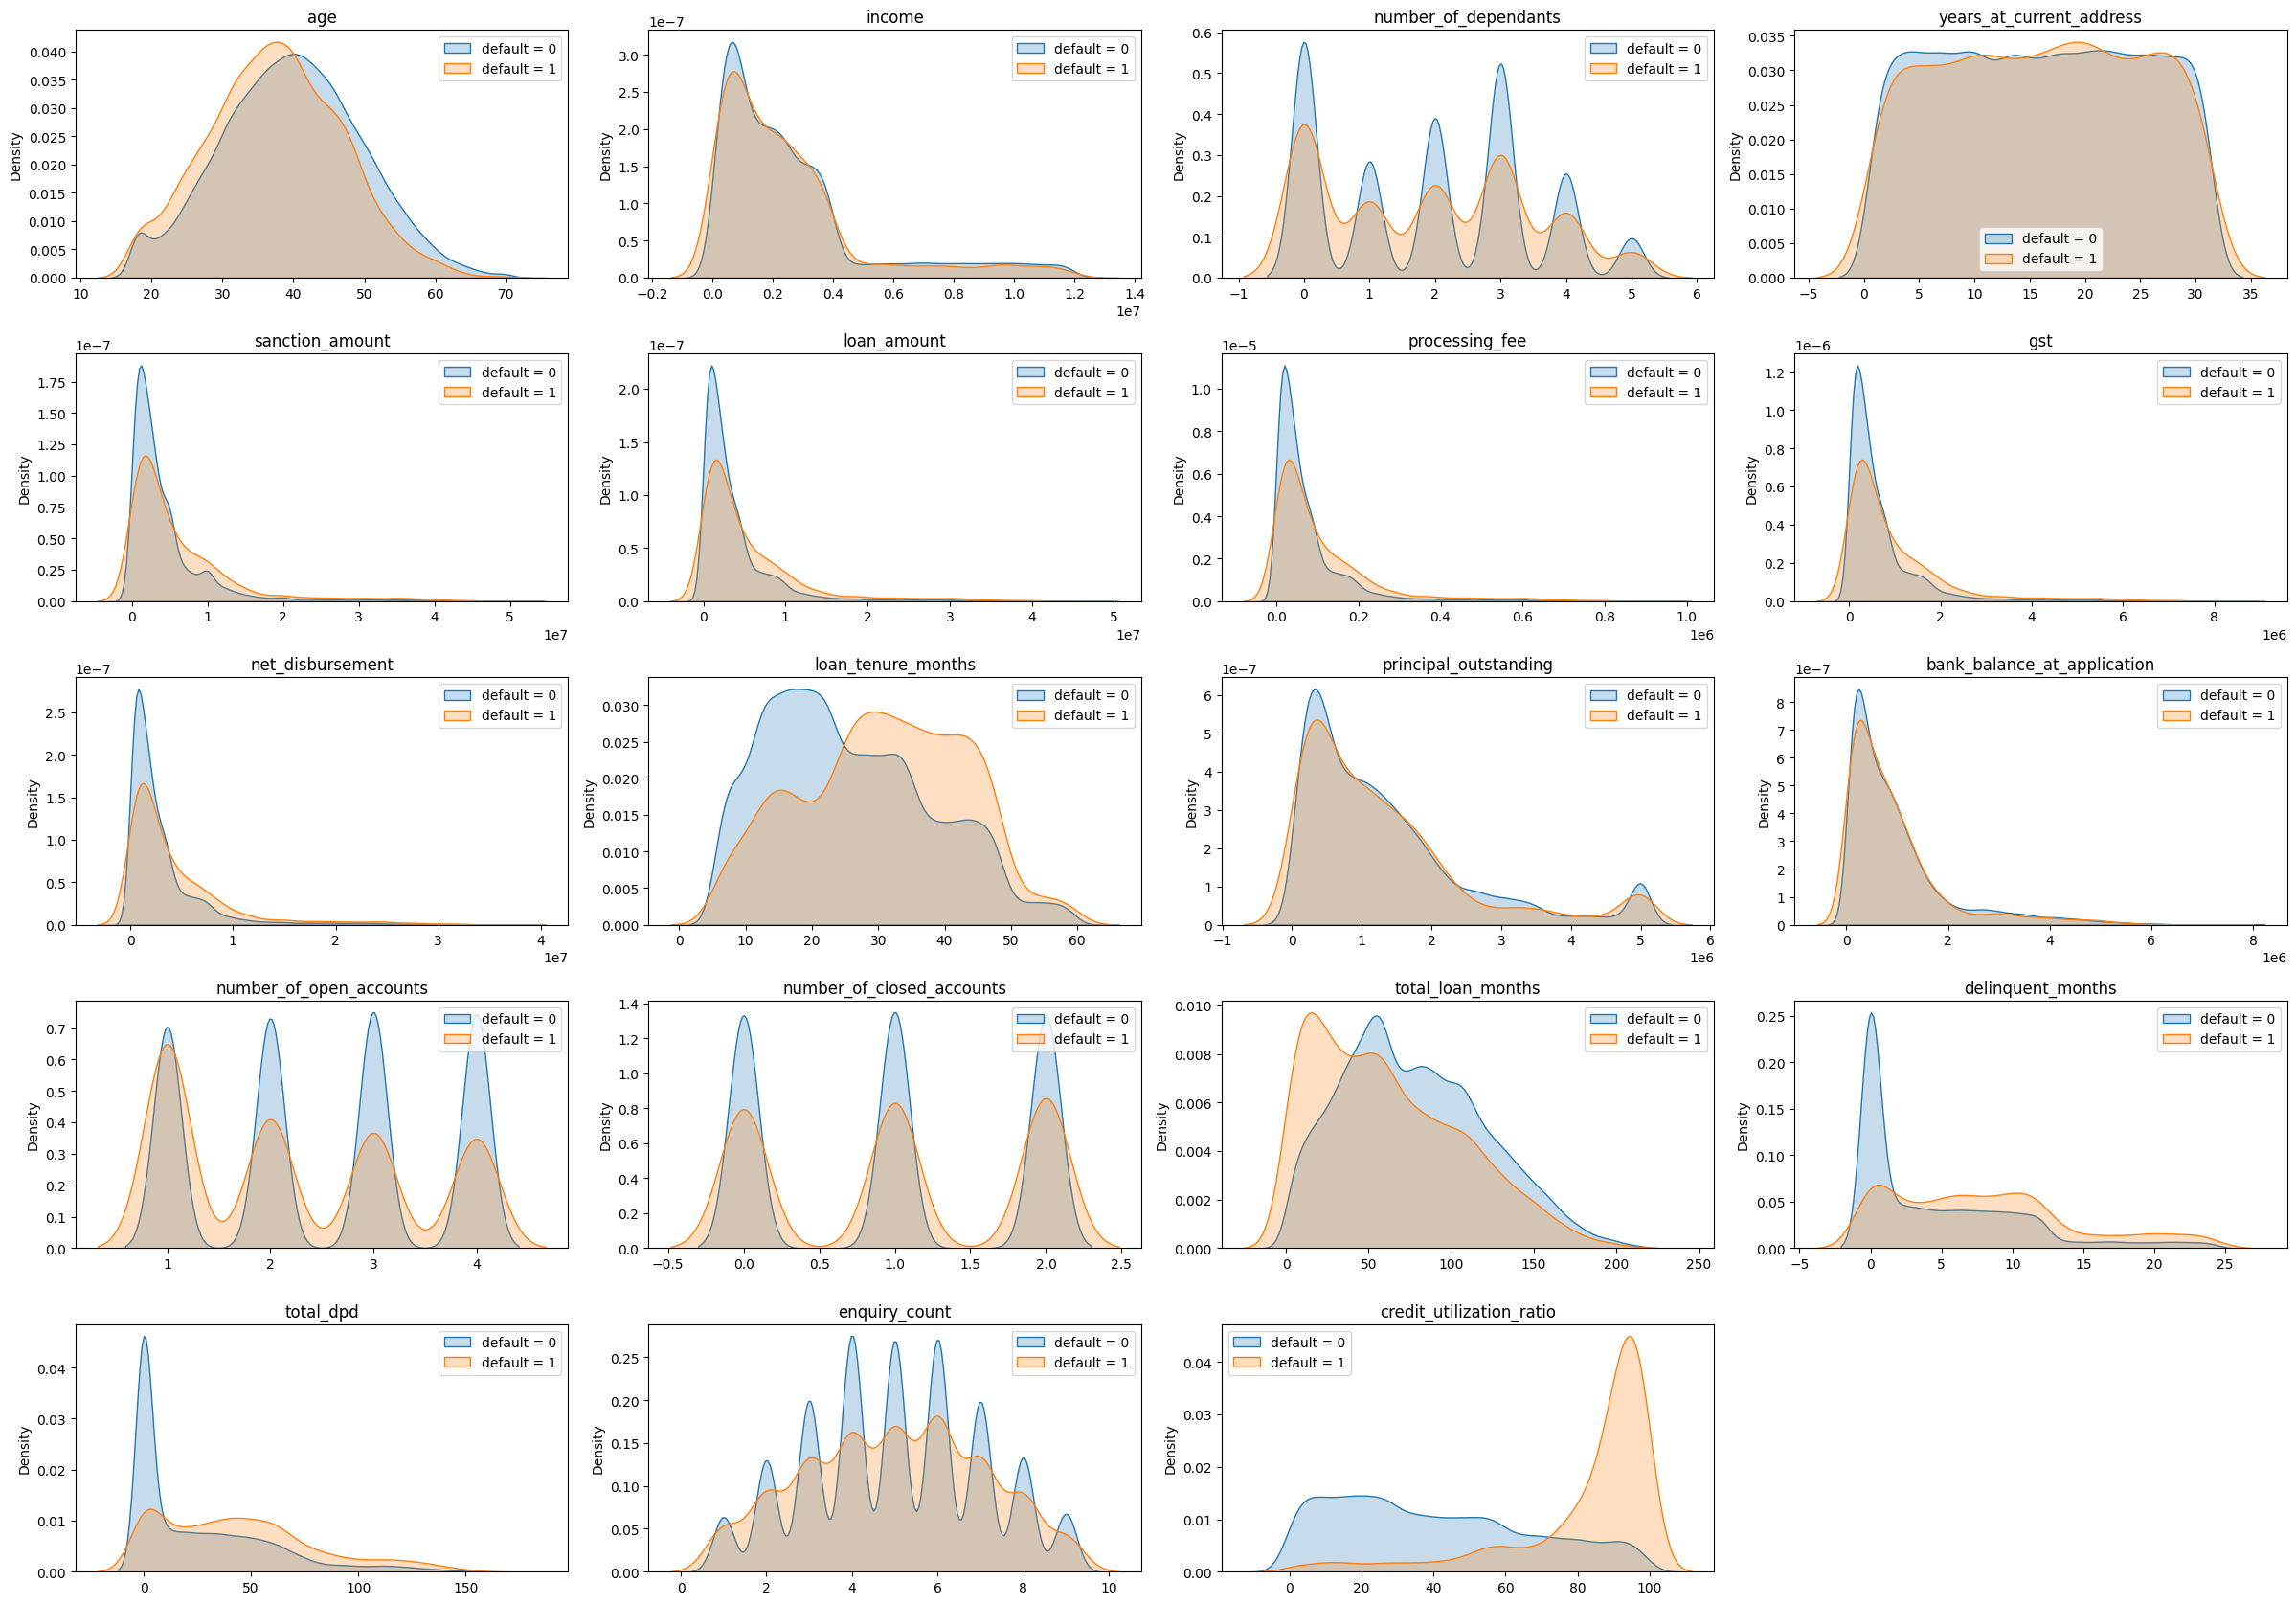

In [35]:
plt.figure(figsize=(24, 20))

for i , col in enumerate(numerical_cols):
    plt.subplot(6, 4, i+1)
    sns.kdeplot(df_train_1[col][df_train_1['default'] == 0], fill=True, label='default = 0')
    sns.kdeplot(df_train_1[col][df_train_1['default'] == 1], fill=True, label='default = 1')
    plt.title(col)
    plt.xlabel('')
    plt.legend()
plt.tight_layout()
plt.show()

**Insights**

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence these 4 looks like strong predictors
1. In remaining columns the distributions do not give any obvious insights
1. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later

<h3 align = "center" style = "color : yellow">Feature Engineering</h3>

In [36]:
df_train_1["loan_to_income_ratio"] = round(df_train_1["loan_amount"] / df_train_1["income"], 2)
df_train_1["loan_to_income_ratio"].describe()

count    39991.000000
mean         1.556321
std          0.971647
min          0.300000
25%          0.770000
50%          1.160000
75%          2.450000
max          4.590000
Name: loan_to_income_ratio, dtype: float64

In [37]:
df_test["loan_to_income_ratio"] = round(df_test["loan_amount"] / df_test["income"], 2)

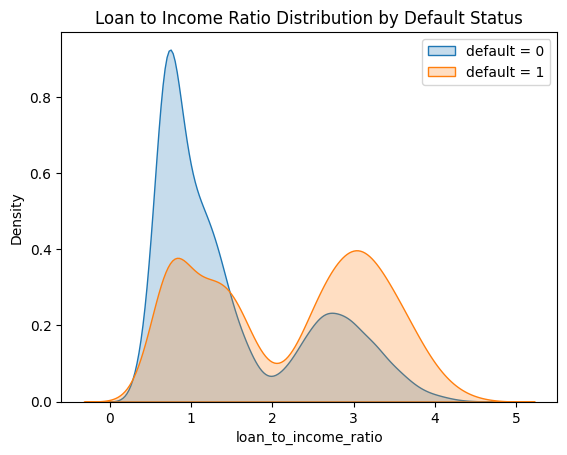

In [38]:
sns.kdeplot(df_train_1[df_train_1.default == 0]['loan_to_income_ratio'], fill=True, label='default = 0')
sns.kdeplot(df_train_1[df_train_1.default == 1]['loan_to_income_ratio'], fill=True, label='default = 1')
plt.title("Loan to Income Ratio Distribution by Default Status")
plt.legend()
plt.show()

In [39]:
df_train_1[["delinquent_months", "total_loan_months"]]

,delinquent_months,total_loan_months
33649,0,19
43700,4,166
27039,0,77
23128,4,46
35305,12,37
...,...,...
27640,0,60
14501,9,12
30727,1,3
47323,4,48


In [40]:
df_train_1["delinquency_ratio"] = round(df_train_1["delinquent_months"]*100 / df_train_1["total_loan_months"], 2)
df_train_1[["delinquent_months", "total_loan_months", "delinquency_ratio"]]

,delinquent_months,total_loan_months,delinquency_ratio
33649,0,19,0.00
43700,4,166,2.41
27039,0,77,0.00
23128,4,46,8.70
35305,12,37,32.43
...,...,...,...
27640,0,60,0.00
14501,9,12,75.00
30727,1,3,33.33
47323,4,48,8.33


In [41]:
df_test["delinquency_ratio"] = round(df_test["delinquent_months"]*100 / df_test["total_loan_months"], 2)

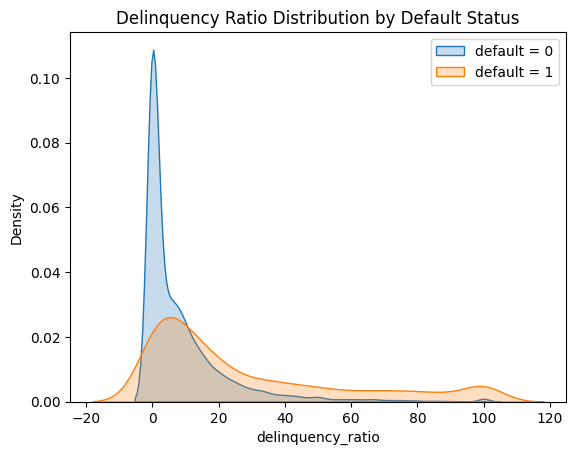

In [42]:
sns.kdeplot(df_train_1[df_train_1.default == 0]['delinquency_ratio'], fill=True, label='default = 0')
sns.kdeplot(df_train_1[df_train_1.default == 1]['delinquency_ratio'], fill=True, label='default = 1')
plt.title("Delinquency Ratio Distribution by Default Status")
plt.legend()
plt.show()

In [43]:
df_train_1["avg_dpd_per_deliquency"] = np.where(
    df_train_1['delinquent_months'] != 0,
    (df_train_1['total_dpd'] / df_train_1['delinquent_months']).round(1),0
)
df_train_1["avg_dpd_per_deliquency"].describe()

count    39991.000000
mean         3.293111
std          2.904702
min          0.000000
25%          0.000000
50%          4.300000
75%          5.700000
max         10.000000
Name: avg_dpd_per_deliquency, dtype: float64

In [44]:
df_test["avg_dpd_per_deliquency"] = np.where(
    df_test['delinquent_months'] != 0,
    (df_test['total_dpd'] / df_test['delinquent_months']).round(1),0
)

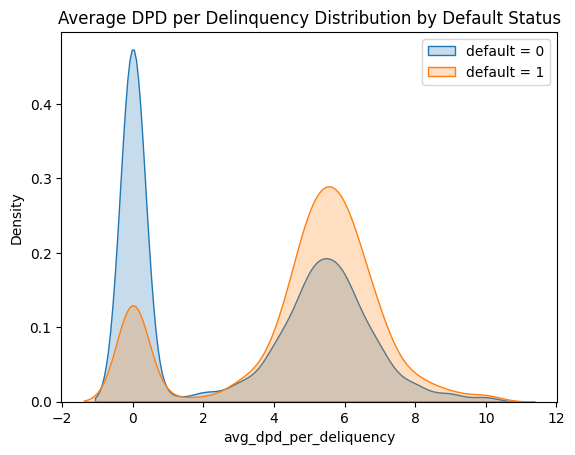

In [45]:
sns.kdeplot(df_train_1[df_train_1.default == 0]['avg_dpd_per_deliquency'], fill=True, label='default = 0')
sns.kdeplot(df_train_1[df_train_1.default == 1]['avg_dpd_per_deliquency'], fill=True, label='default = 1')
plt.title("Average DPD per Delinquency Distribution by Default Status")
plt.legend()
plt.show()

<h3 align = "center" style = "color : yellow">Feature Selection: Numerical</h3>

In [46]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income_ratio', 'delinquency_ratio', 'avg_dpd_per_deliquency'],
      dtype='str')

In [47]:
df_train_2 = df_train_1.drop(['cust_id', 'loan_id'], axis='columns')
df_test = df_test.drop(['cust_id', 'loan_id'], axis='columns')


In [48]:
df_train_3 = df_train_2.drop(['disbursal_date', 'installment_start_dt', 'income', 'loan_amount', 'total_loan_months', 'delinquent_months', 'total_dpd'], axis='columns')
#df_test = df_test.drop(['disbursal_date', 'installment_start_dt', 'income', 'loan_amount', 'total_loan_months', 'delinquent_months', 'total_dpd'], axis='columns')
df_train_3.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquency_ratio', 'avg_dpd_per_deliquency'],
      dtype='str')

In [49]:
df_train_3.info()

<class 'pandas.DataFrame'>
Index: 39991 entries, 33649 to 11590
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          39991 non-null  int64  
 1   gender                       39991 non-null  str    
 2   marital_status               39991 non-null  str    
 3   employment_status            39991 non-null  str    
 4   number_of_dependants         39991 non-null  int64  
 5   residence_type               39991 non-null  str    
 6   years_at_current_address     39991 non-null  int64  
 7   city                         39991 non-null  str    
 8   state                        39991 non-null  str    
 9   zipcode                      39991 non-null  int64  
 10  loan_purpose                 39991 non-null  str    
 11  loan_type                    39991 non-null  str    
 12  sanction_amount              39991 non-null  int64  
 13  processing_fee              

In [50]:
df_train_3.select_dtypes(['int64', 'float64']).columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income_ratio',
       'delinquency_ratio', 'avg_dpd_per_deliquency'],
      dtype='str')

In [51]:
X_train = df_train_3.drop(['default','zipcode'], axis=1)
y_train = df_train_3['default']

In [52]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
columns_to_scale = X_train.select_dtypes(['int64', 'float64']).columns
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_train.describe()

,age,number_of_dependants,years_at_current_address,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income_ratio,delinquency_ratio,avg_dpd_per_deliquency
count,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000,39991.000000
mean,0.414338,0.388447,0.500056,0.089114,0.082881,0.082881,0.082881,0.376329,0.262659,0.124112,0.499804,0.500275,0.500947,0.437959,0.292849,0.103491,0.329311
std,0.189384,0.307060,0.297464,0.120344,0.112753,0.112753,0.112753,0.234261,0.245260,0.133900,0.372731,0.407190,0.254016,0.296196,0.226491,0.172431,0.290470
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.288462,0.000000,0.233333,0.020709,0.019238,0.019238,0.019238,0.188679,0.078324,0.034190,0.000000,0.000000,0.375000,0.181818,0.109557,0.000000,0.000000
50%,0.423077,0.400000,0.500000,0.049555,0.045846,0.045846,0.045846,0.339623,0.194992,0.083029,0.666667,0.500000,0.500000,0.393939,0.200466,0.037600,0.430000
75%,0.538462,0.600000,0.766667,0.098390,0.095836,0.095836,0.095836,0.547170,0.353702,0.156009,0.666667,1.000000,0.625000,0.676768,0.501166,0.129900,0.570000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [53]:
X_test = df_test.drop(['default','zipcode'], axis=1)
y_test = df_test['default']

X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])
X_test.describe()

,age,income,number_of_dependants,years_at_current_address,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,loan_to_income_ratio,delinquency_ratio,avg_dpd_per_deliquency
count,9994.000000,9.994000e+03,9994.000000,9994.000000,9994.000000,9.994000e+03,9994.000000,9994.000000,9994.000000,9994.000000,...,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.00000
mean,0.414797,2.628379e+06,0.385711,0.502842,0.088304,3.965929e+06,0.081976,0.081976,0.081976,0.375916,...,0.500867,0.501551,76.199220,4.960676,27.389033,0.502089,0.438161,0.291719,0.106009,0.33153
std,0.189395,2.624657e+06,0.307295,0.297892,0.120106,5.340904e+06,0.111807,0.111807,0.111807,0.235924,...,0.373709,0.406557,43.786456,5.910449,33.286570,0.252199,0.297883,0.226571,0.175306,0.29025
min,0.000000,1.000000e+05,0.000000,0.000000,0.000058,6.600000e+04,0.000335,0.000335,0.000335,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,0.288462,7.962500e+05,0.000000,0.233333,0.020459,9.570000e+05,0.018987,0.018987,0.018987,0.188679,...,0.333333,0.000000,42.000000,0.000000,0.000000,0.375000,0.181818,0.109557,0.000000,0.00000
50%,0.423077,1.880000e+06,0.400000,0.500000,0.049862,2.241000e+06,0.045867,0.045867,0.045867,0.339623,...,0.333333,0.500000,72.000000,3.000000,14.000000,0.500000,0.393939,0.200466,0.039700,0.44000
75%,0.538462,3.348000e+06,0.600000,0.766667,0.096216,4.558750e+06,0.094387,0.094387,0.094387,0.547170,...,1.000000,1.000000,107.000000,9.000000,47.000000,0.625000,0.676768,0.501166,0.133300,0.58000
max,1.000000,1.199600e+07,1.000000,1.000000,0.981249,4.381400e+07,0.916159,0.916159,0.916159,1.000000,...,1.000000,1.000000,223.000000,24.000000,171.000000,1.000000,1.000000,0.976690,1.000000,1.00000


In [54]:
X_train[columns_to_scale].head(2)

,age,number_of_dependants,years_at_current_address,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income_ratio,delinquency_ratio,avg_dpd_per_deliquency
33649,0.365385,0.6,0.833333,0.025200,0.025791,0.025791,0.025791,0.528302,0.088227,0.040882,0.000000,0.0,0.00,0.313131,0.212121,0.0000,0.00
43700,0.461538,0.0,0.066667,0.006832,0.005924,0.005924,0.005924,0.264151,0.025543,0.015669,0.666667,0.0,0.25,0.171717,0.205128,0.0241,0.58


In [55]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_data = pd.DataFrame()
    vif_data["Column"] = data.columns
    vif_data["VIF"] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_data

In [56]:
calculate_vif(X_train[columns_to_scale])

C:\Users\ittis\AppData\Local\Temp\ipykernel_15480\3215585265.py:6: UserWarning: The design matrix is poorly conditioned (condition number=8.42e+16). VIF calculations may be numerically unstable.
  vif_data["VIF"] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
C:\Users\ittis\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\ittis\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\ittis\AppData\Local\Packages\Pyt

,Column,VIF
0,age,1.157036e+00
1,number_of_dependants,1.071083e+00
2,years_at_current_address,1.000366e+00
3,sanction_amount,6.549884e+01
4,processing_fee,1.000800e+15
5,gst,1.000800e+15
6,net_disbursement,1.000800e+15
7,loan_tenure_months,1.733778e+00
8,principal_outstanding,7.635149e+00
9,bank_balance_at_application,5.140529e+00


In [57]:
features_to_drop = ['processing_fee', 'gst', 'principal_outstanding', 'sanction_amount','net_disbursement']

X_train_1 = X_train.drop(features_to_drop, axis=1)
numeric_col = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_col

Index(['age', 'number_of_dependants', 'years_at_current_address',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income_ratio', 'delinquency_ratio',
       'avg_dpd_per_deliquency'],
      dtype='str')

In [58]:
vif_df = calculate_vif(X_train_1[numeric_col])
vif_df

,Column,VIF
0,age,1.122032
1,number_of_dependants,1.071066
2,years_at_current_address,1.000285
3,loan_tenure_months,1.695020
4,bank_balance_at_application,1.003184
5,number_of_open_accounts,1.559632
6,number_of_closed_accounts,1.000312
7,enquiry_count,1.411765
8,credit_utilization_ratio,1.000485
9,loan_to_income_ratio,1.745567


In [59]:
selected_features_for_vif = vif_df.Column.values
selected_features_for_vif

<ArrowStringArray>
[                        'age',        'number_of_dependants',
    'years_at_current_address',          'loan_tenure_months',
 'bank_balance_at_application',     'number_of_open_accounts',
   'number_of_closed_accounts',               'enquiry_count',
    'credit_utilization_ratio',        'loan_to_income_ratio',
           'delinquency_ratio',      'avg_dpd_per_deliquency']
Length: 12, dtype: str

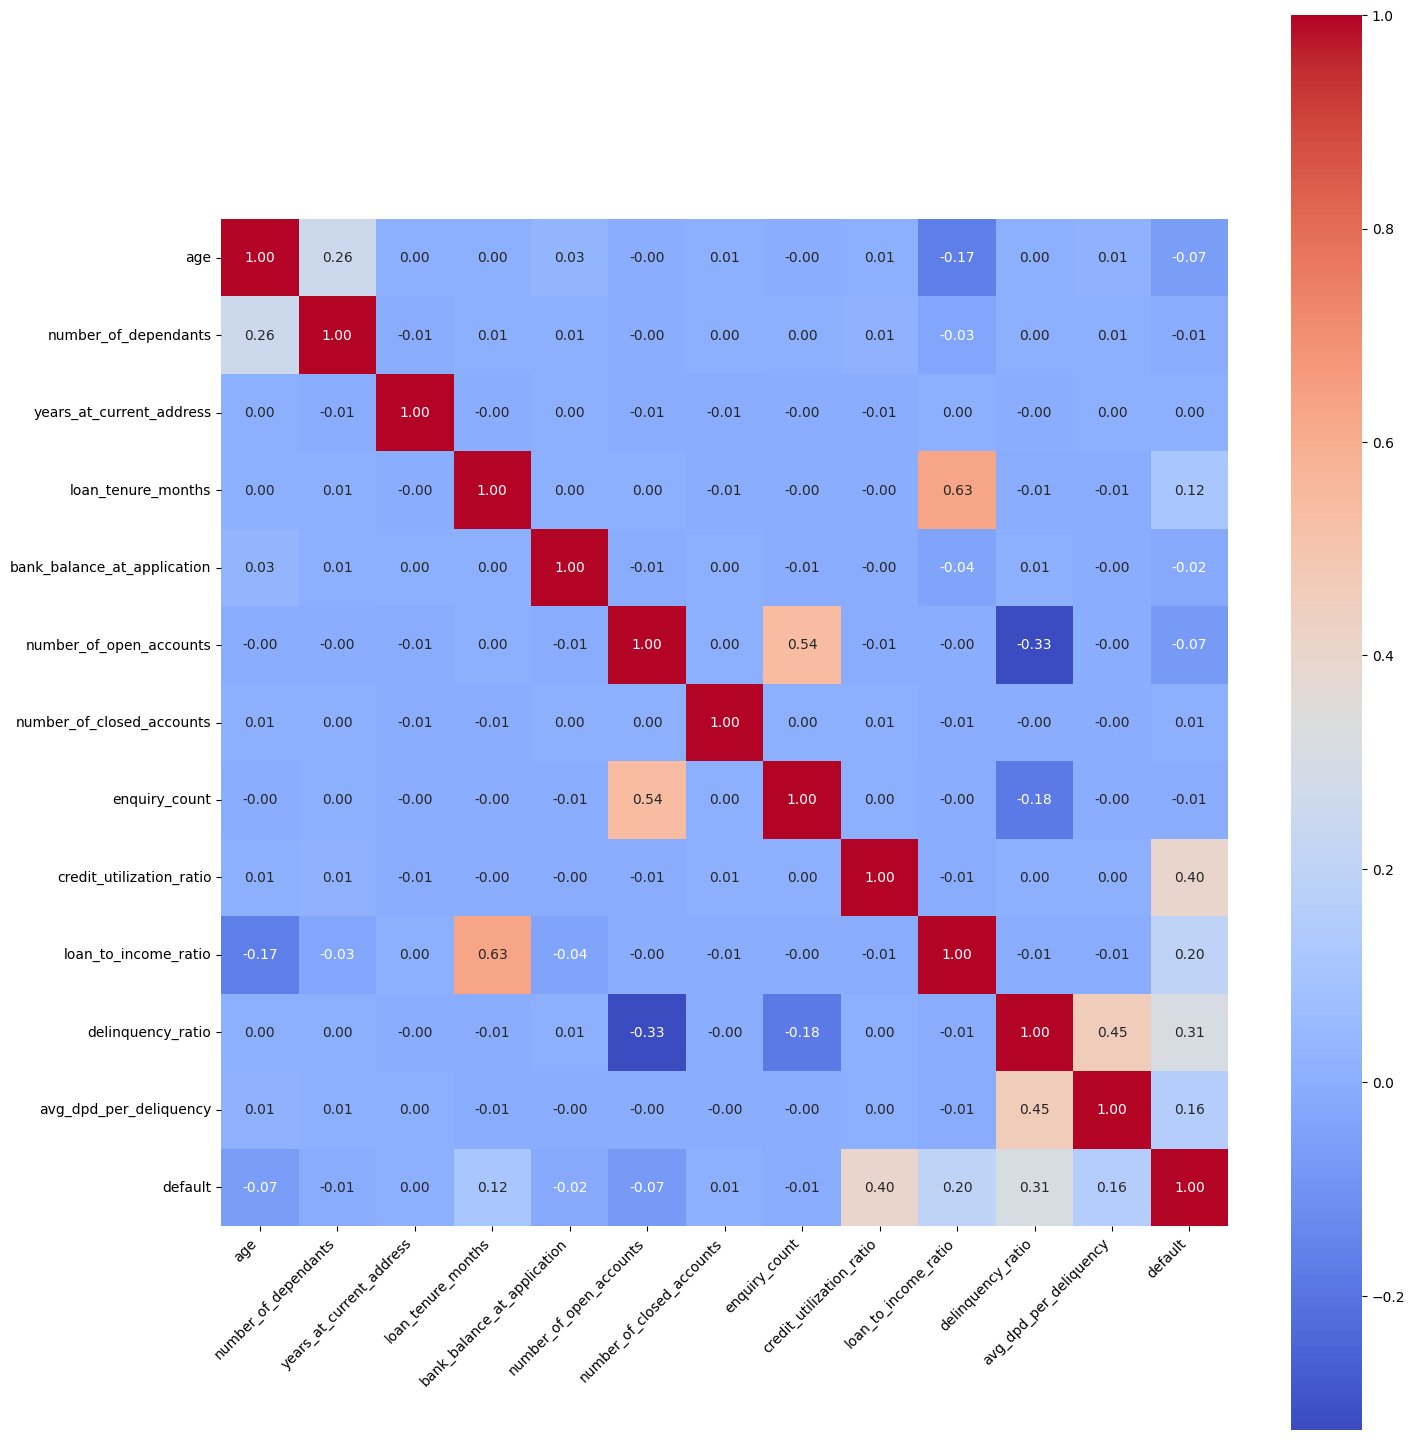

In [60]:
plt.figure(figsize=(15, 15))
cm = df_train_3[numeric_col.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.xticks(rotation=45,ha = 'right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

<h3 align = "center" style = "color : yellow">Feature Selection: Categorical</h3>

In [70]:
def calculate_woe_iv(df, feature, target):
    lst = []
    for i in range(df[feature].nunique()):
        val = list(df[feature].unique())[i]
        total = df[df[feature] == val].count()[feature]
        bad = df[(df[feature] == val) & (df[target] == 1)].count()[feature]
        good = df[(df[feature] == val) & (df[target] == 0)].count()[feature]
        lst.append([val, total, bad, good])
    data = pd.DataFrame(lst, columns=[feature, 'Total', 'Bad', 'Good'])
    data['Bad Rate'] = data['Bad'] / data['Total']
    data['Good Rate'] = data['Good'] / data['Total']
    data['Distribution Bad'] = data['Bad'] / data['Bad'].sum()
    data['Distribution Good'] = data['Good'] / data['Good'].sum()
    data['WoE'] = np.log(data['Distribution Good'] / data['Distribution Bad'])
    data['IV'] = (data['Distribution Good'] - data['Distribution Bad']) * data['WoE']
    iv = data['IV'].sum()
    return data, iv

data, iv = calculate_woe_iv(pd.concat([ X_train_1 , y_train], axis=1), 'loan_purpose', 'default')
data


,loan_purpose,Total,Bad,Good,Bad Rate,Good Rate,Distribution Bad,Distribution Good,WoE,IV
0,Auto,7917,327,7590,0.041304,0.958696,0.096574,0.207349,0.764091,0.084642
1,Education,6067,585,5482,0.096423,0.903577,0.172770,0.149761,-0.142922,0.003289
2,Home,12035,1832,10203,0.152223,0.847777,0.541051,0.278732,-0.663262,0.173986
3,Personal,13972,642,13330,0.045949,0.954051,0.189604,0.364158,0.652649,0.113922


In [72]:
df_new = pd.concat([ X_train_1 , y_train], axis=1)

In [78]:
iv_values = {}

categorical_cols = X_train_1.select_dtypes(include=['object', 'category']).columns

for feature in X_train_1.columns:

    if feature in categorical_cols:
        _, iv = calculate_woe_iv(
            pd.concat([X_train_1, y_train], axis=1),
            feature,
            'default'
        )

    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)

        temp_df = pd.DataFrame({
            feature: X_binned,
            'default': y_train
        })

        _, iv = calculate_woe_iv(temp_df, feature, 'default')

    iv_values[feature] = iv

iv_values

C:\Users\ittis\AppData\Local\Temp\ipykernel_15480\3359730335.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train_1.select_dtypes(include=['object', 'category']).columns


{'age': np.float64(0.06782148833696061),
 'gender': np.float64(0.0002011103449865669),
 'marital_status': np.float64(0.0018277724638337564),
 'employment_status': np.float64(0.0023031606381473456),
 'number_of_dependants': np.float64(0.0034442957990919215),
 'residence_type': np.float64(0.25495283716593936),
 'years_at_current_address': np.float64(0.0016762221316494754),
 'city': np.float64(0.0013386123699822576),
 'state': np.float64(0.0012442043772172167),
 'loan_purpose': np.float64(0.37583882135397995),
 'loan_type': np.float64(0.1562640916529018),
 'loan_tenure_months': np.float64(0.21289751497842607),
 'bank_balance_at_application': np.float64(0.0057501681219872414),
 'number_of_open_accounts': np.float64(0.0798025654190857),
 'number_of_closed_accounts': np.float64(0.0011389094060228005),
 'enquiry_count': np.float64(0.006495087747197695),
 'credit_utilization_ratio': np.float64(2.4408780986505816),
 'loan_to_income_ratio': np.float64(0.46154286864250726),
 'delinquency_ratio': 

In [79]:
iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
16,credit_utilization_ratio,2.440878
18,delinquency_ratio,0.698728
17,loan_to_income_ratio,0.461543
19,avg_dpd_per_deliquency,0.410434
9,loan_purpose,0.375839
5,residence_type,0.254953
11,loan_tenure_months,0.212898
10,loan_type,0.156264
13,number_of_open_accounts,0.079803
0,age,0.067821


In [80]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income_ratio',
 'delinquency_ratio',
 'avg_dpd_per_deliquency']

In [81]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

In [82]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_train_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income_ratio,delinquency_ratio,avg_dpd_per_deliquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
33649,0.365385,0.528302,0.000000,0.313131,0.212121,0.0000,0.00,True,False,False,False,False,False
43700,0.461538,0.264151,0.666667,0.171717,0.205128,0.0241,0.58,True,False,True,False,False,False
27039,0.653846,0.735849,0.666667,0.181818,0.652681,0.0000,0.00,True,False,False,True,False,False


In [83]:
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)
X_test_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income_ratio,delinquency_ratio,avg_dpd_per_deliquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
22599,0.230769,0.339623,1.000000,0.242424,0.662005,0.0,0.0,True,False,False,True,False,False
38540,0.000000,0.188679,0.333333,0.989899,0.102564,0.0,0.0,True,False,False,False,False,False
32995,0.288462,0.735849,0.666667,0.686869,0.519814,0.0,0.0,True,False,False,True,False,False
